In [1]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Step 2: Load Datasets

orders = pd.read_csv("../data/processed/orders_cleaned.csv")

order_items = pd.read_csv(
    "../data/raw/olist_order_items_dataset.csv"
)

products = pd.read_csv(
    "../data/processed/products_cleaned.csv"
)

sellers = pd.read_csv(
    "../data/raw/olist_sellers_dataset.csv"
)

print("ORDERS:", orders.shape)
print("ORDER ITEMS:", order_items.shape)
print("PRODUCTS:", products.shape)
print("SELLERS:", sellers.shape)

ORDERS: (99441, 12)
ORDER ITEMS: (112650, 7)
PRODUCTS: (32951, 16)
SELLERS: (3095, 4)


In [3]:
# Step 3: Create Late Delivery Target

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce"
)

# Keep only delivered orders with valid delivery dates
ml_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
].copy()

# Compare calendar dates
actual_date = ml_orders["order_delivered_customer_date"].dt.normalize()
estimated_date = ml_orders["order_estimated_delivery_date"].dt.normalize()

# Create target variable
ml_orders["late_delivery"] = (
    actual_date > estimated_date
).astype(int)

print("Total eligible orders:", len(ml_orders))
print("\nLate delivery distribution:")
print(ml_orders["late_delivery"].value_counts())

print("\nLate delivery percentage:")
print(
    (ml_orders["late_delivery"].value_counts(normalize=True) * 100).round(2)
)

Total eligible orders: 96470

Late delivery distribution:
late_delivery
0    89936
1     6534
Name: count, dtype: int64

Late delivery percentage:
late_delivery
0    93.23
1     6.77
Name: proportion, dtype: float64


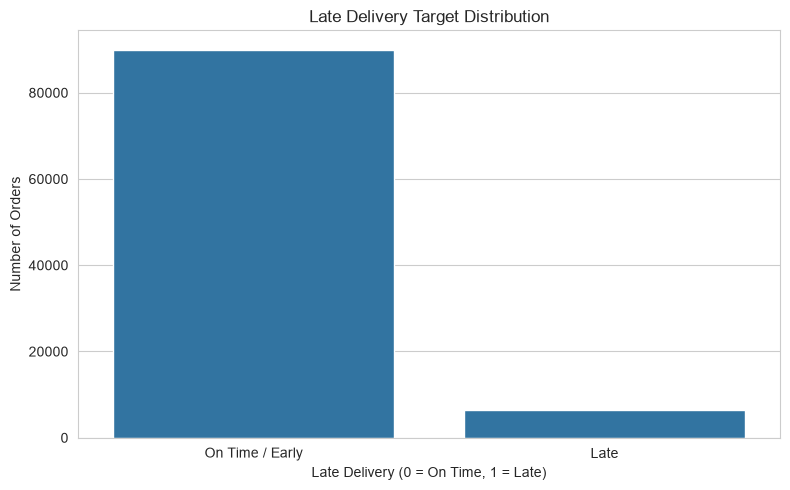

In [4]:
# Step 4: Visualize Target Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=ml_orders,
    x="late_delivery"
)

plt.title("Late Delivery Target Distribution")
plt.xlabel("Late Delivery (0 = On Time, 1 = Late)")
plt.ylabel("Number of Orders")
plt.xticks([0, 1], ["On Time / Early", "Late"])

plt.tight_layout()
plt.show()

In [5]:
# Step 5: Aggregate Order-Level Features

# Select relevant product information
product_features = products[
    ["product_id", "product_category_name", "product_weight_g"]
].copy()

# Select seller location
seller_features = sellers[
    ["seller_id", "seller_state"]
].copy()

# Merge order items with product information
items_data = order_items.merge(
    product_features,
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Merge seller information
items_data = items_data.merge(
    seller_features,
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# Helper function to find the most common value
def get_mode(series):
    mode_values = series.dropna().mode()
    return mode_values.iloc[0] if not mode_values.empty else np.nan

# Aggregate item information to order level
order_features = (
    items_data.groupby("order_id")
    .agg(
        total_items=("order_item_id", "count"),
        unique_sellers=("seller_id", "nunique"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        average_price=("price", "mean"),
        average_freight=("freight_value", "mean"),
        average_product_weight=("product_weight_g", "mean"),
        unique_categories=("product_category_name", "nunique"),
        main_category=("product_category_name", get_mode),
        main_seller_state=("seller_state", get_mode)
    )
    .reset_index()
)

print("Order-level features shape:", order_features.shape)
display(order_features.head())

Order-level features shape: (98666, 11)


,order_id,total_items,unique_sellers,total_price,total_freight,average_price,average_freight,average_product_weight,unique_categories,main_category,main_seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.90,13.29,58.90,13.29,650.0,1,cool_stuff,SP
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.90,19.93,239.90,19.93,30000.0,1,pet_shop,SP
2,000229ec398224ef6ca0657da4fc703e,1,1,199.00,17.87,199.00,17.87,3050.0,1,moveis_decoracao,MG
3,00024acbcdf0a6daa1e931b038114c75,1,1,12.99,12.79,12.99,12.79,200.0,1,perfumaria,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,199.90,18.14,199.90,18.14,3750.0,1,ferramentas_jardim,PR


In [8]:
# Step 6: Create Order-Time Features

# Convert timestamps
ml_orders["order_purchase_timestamp"] = pd.to_datetime(
    ml_orders["order_purchase_timestamp"],
    errors="coerce"
)

ml_orders["order_estimated_delivery_date"] = pd.to_datetime(
    ml_orders["order_estimated_delivery_date"],
    errors="coerce"
)

# Extract purchase-time features
ml_orders["purchase_year"] = (
    ml_orders["order_purchase_timestamp"].dt.year
)

ml_orders["purchase_month"] = (
    ml_orders["order_purchase_timestamp"].dt.month
)

ml_orders["purchase_day"] = (
    ml_orders["order_purchase_timestamp"].dt.day
)

ml_orders["purchase_dayofweek"] = (
    ml_orders["order_purchase_timestamp"].dt.dayofweek
)

ml_orders["purchase_hour"] = (
    ml_orders["order_purchase_timestamp"].dt.hour
)

ml_orders["is_weekend"] = (
    ml_orders["purchase_dayofweek"] >= 5
).astype(int)

# Calculate estimated delivery window in days
ml_orders["estimated_delivery_days"] = (
    ml_orders["order_estimated_delivery_date"].dt.normalize()
    - ml_orders["order_purchase_timestamp"].dt.normalize()
).dt.days

# Merge customer state
customer_features = customers[
    ["customer_id", "customer_state"]
].copy()

ml_orders = ml_orders.merge(
    customer_features,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

print("Order-time features created.")
display(
    ml_orders[
        [
            "order_id",
            "purchase_month",
            "purchase_dayofweek",
            "purchase_hour",
            "is_weekend",
            "estimated_delivery_days",
            "customer_state",
            "late_delivery"
        ]
    ].head()
)

C:\Users\Rakesh bade\AppData\Local\Temp\ipykernel_41524\56678224.py:28: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ml_orders["order_purchase_timestamp"].dt.dayofweek


Order-time features created.


,order_id,purchase_month,purchase_dayofweek,purchase_hour,is_weekend,estimated_delivery_days,customer_state,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,10,0,10,0,16,SP,0
1,53cdb2fc8bc7dce0b6741e2150273451,7,1,20,0,20,BA,0
2,47770eb9100c2d0c44946d9cf07ec65d,8,2,8,0,27,GO,0
3,949d5b44dbf5de918fe9c16f97b45f8a,11,5,19,1,27,RN,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2,1,21,0,13,SP,0


In [7]:
# Load customer dataset

customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv"
)

print("Customers shape:", customers.shape)
display(customers.head())

Customers shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [9]:
# Step 7: Combine All Features

ml_data = ml_orders.merge(
    order_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Final ML dataset shape:", ml_data.shape)

print("\nMissing values:")
print(ml_data.isnull().sum())

print("\nSample records:")
display(ml_data.head())

Final ML dataset shape: (96470, 31)

Missing values:
order_id                                  0
customer_id                               0
order_status                              0
order_purchase_timestamp                  0
order_approved_at                        14
order_delivered_carrier_date              1
order_delivered_customer_date             0
order_estimated_delivery_date             0
delivery_date_issue                       0
order_approved_at_missing                 0
order_delivered_carrier_date_missing      0
order_delivered_customer_date_missing     0
late_delivery                             0
purchase_year                             0
purchase_month                            0
purchase_day                              0
purchase_dayofweek                        0
purchase_hour                             0
is_weekend                                0
estimated_delivery_days                   0
customer_state                            0
total_items            

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_issue,order_approved_at_missing,order_delivered_carrier_date_missing,order_delivered_customer_date_missing,late_delivery,purchase_year,purchase_month,purchase_day,purchase_dayofweek,purchase_hour,is_weekend,estimated_delivery_days,customer_state,total_items,unique_sellers,total_price,total_freight,average_price,average_freight,average_product_weight,unique_categories,main_category,main_seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,0,0,0,0,2017,10,2,0,10,0,16,SP,1,1,29.99,8.72,29.99,8.72,500.0,1,utilidades_domesticas,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,0,0,0,0,2018,7,24,1,20,0,20,BA,1,1,118.70,22.76,118.70,22.76,400.0,1,perfumaria,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,0,0,0,0,2018,8,8,2,8,0,27,GO,1,1,159.90,19.22,159.90,19.22,420.0,1,automotivo,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,0,0,0,0,2017,11,18,5,19,1,27,RN,1,1,45.00,27.20,45.00,27.20,450.0,1,pet_shop,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,0,0,0,0,2018,2,13,1,21,0,13,SP,1,1,19.90,8.72,19.90,8.72,250.0,1,papelaria,SP


In [10]:
# Step 8: Select Features and Target

feature_columns = [
    # Purchase-time features
    "purchase_year",
    "purchase_month",
    "purchase_day",
    "purchase_dayofweek",
    "purchase_hour",
    "is_weekend",
    "estimated_delivery_days",

    # Customer and seller location
    "customer_state",
    "main_seller_state",

    # Order and product features
    "total_items",
    "unique_sellers",
    "total_price",
    "total_freight",
    "average_price",
    "average_freight",
    "average_product_weight",
    "unique_categories",
    "main_category"
]

X = ml_data[feature_columns].copy()
y = ml_data["late_delivery"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nNumerical features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include="object").columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature dataset shape: (96470, 18)
Target dataset shape: (96470,)

Numerical features:
['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_hour', 'is_weekend', 'estimated_delivery_days', 'total_items', 'unique_sellers', 'total_price', 'total_freight', 'average_price', 'average_freight', 'average_product_weight', 'unique_categories']

Categorical features:
['customer_state', 'main_seller_state', 'main_category']

Target distribution:
late_delivery
0    89936
1     6534
Name: count, dtype: int64


C:\Users\Rakesh bade\AppData\Local\Temp\ipykernel_41524\3635120266.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include="object").columns.tolist())


In [11]:
# Step 9: Time-Based Train-Test Split

# Sort orders chronologically
ml_data_sorted = ml_data.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

# Recreate X and y in chronological order
X_sorted = ml_data_sorted[feature_columns].copy()
y_sorted = ml_data_sorted["late_delivery"].copy()

# Use first 80% for training and last 20% for testing
split_index = int(len(ml_data_sorted) * 0.80)

X_train = X_sorted.iloc[:split_index]
X_test = X_sorted.iloc[split_index:]

y_train = y_sorted.iloc[:split_index]
y_test = y_sorted.iloc[split_index:]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining period:")
print(ml_data_sorted["order_purchase_timestamp"].iloc[0])
print("to")
print(ml_data_sorted["order_purchase_timestamp"].iloc[split_index - 1])

print("\nTesting period:")
print(ml_data_sorted["order_purchase_timestamp"].iloc[split_index])
print("to")
print(ml_data_sorted["order_purchase_timestamp"].iloc[-1])

print("\nTraining target distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (77176, 18)
Testing features: (19294, 18)

Training period:
2016-09-15 12:16:38
to
2018-05-26 18:16:57

Testing period:
2018-05-26 18:18:03
to
2018-08-29 15:00:37

Training target distribution:
late_delivery
0    92.41
1     7.59
Name: proportion, dtype: float64

Testing target distribution:
late_delivery
0    96.51
1     3.49
Name: proportion, dtype: float64


In [12]:
# Step 10: Create Preprocessing Pipeline

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(feature_columns))

Preprocessing pipeline created successfully.

Numerical features: 15
Categorical features: 3
Total input features: 18


In [13]:
# Step 11: Train Logistic Regression Model

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [14]:
# Step 12: Train Random Forest Model

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [15]:
# Step 13: Train Gradient Boosting Model

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [16]:
# Step 14: Evaluate All Models

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

results = []

for model_name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.2865,0.0443,0.9436,0.0846,0.6851
2,Gradient Boosting,0.9648,0.2000,0.0030,0.0058,0.5739
1,Random Forest,0.7641,0.0435,0.2745,0.0752,0.5056


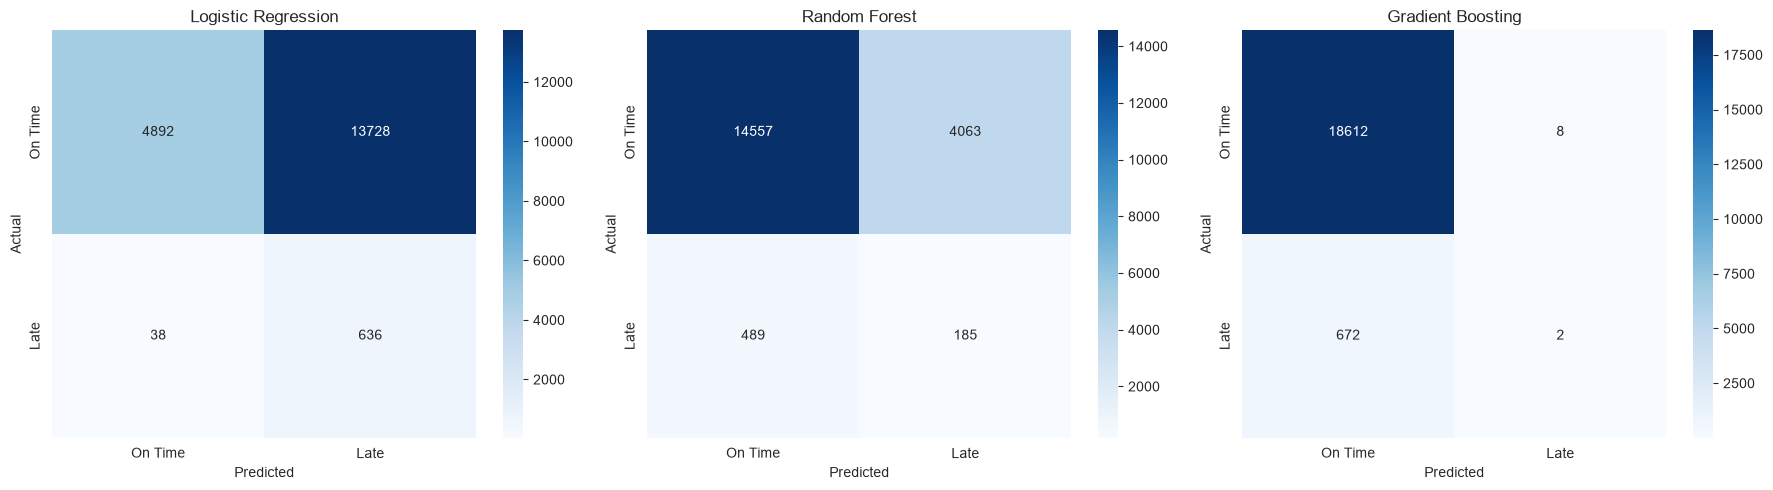

In [17]:
# Step 15: Confusion Matrix Comparison

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["On Time", "Late"],
        yticklabels=["On Time", "Late"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [18]:
# Count predicted late orders

for model_name, model in models.items():

    predictions = model.predict(X_test)

    print("\n", model_name)
    print("Actual late orders:", int(y_test.sum()))
    print("Predicted late orders:", int(predictions.sum()))


 Logistic Regression
Actual late orders: 674
Predicted late orders: 14364

 Random Forest
Actual late orders: 674
Predicted late orders: 4248

 Gradient Boosting
Actual late orders: 674
Predicted late orders: 10


In [19]:
# Step 16: Create Chronological Validation Set

validation_split = int(len(X_train) * 0.80)

X_fit = X_train.iloc[:validation_split]
X_val = X_train.iloc[validation_split:]

y_fit = y_train.iloc[:validation_split]
y_val = y_train.iloc[validation_split:]

print("Model fitting data:", X_fit.shape)
print("Validation data:", X_val.shape)

print("\nValidation target distribution:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nValidation late orders:", y_val.sum())

Model fitting data: (61740, 18)
Validation data: (15436, 18)

Validation target distribution:
late_delivery
0    93.31
1     6.69
Name: proportion, dtype: float64

Validation late orders: 1032


In [20]:
# Step 17: Train Logistic Regression on Fitting Data

validation_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

validation_model.fit(X_fit, y_fit)

# Predict probabilities on validation data
val_probabilities = validation_model.predict_proba(X_val)[:, 1]

print("Validation model trained successfully.")
print("Validation probabilities:", len(val_probabilities))
print("Minimum probability:", round(val_probabilities.min(), 4))
print("Maximum probability:", round(val_probabilities.max(), 4))

Validation model trained successfully.
Validation probabilities: 15436
Minimum probability: 0.0324
Maximum probability: 0.9974


In [21]:
# Step 18: Threshold Comparison on Validation Data

from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Predicted_Late": predictions.sum(),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Predicted_Late,Precision,Recall,F1_Score
0,0.5,13816,0.0731,0.9787,0.1360
1,0.6,11025,0.0848,0.9060,0.1551
2,0.7,6069,0.1203,0.7074,0.2056
3,0.8,2642,0.1688,0.4322,0.2428
4,0.9,338,0.2071,0.0678,0.1022


In [22]:
# Step 19: Final Logistic Regression Evaluation

selected_threshold = 0.80

# Predict probabilities on unseen test data
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
final_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Calculate evaluation metrics
print("FINAL MODEL PERFORMANCE")
print("-" * 40)

print("Threshold:", selected_threshold)

print("Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test, final_predictions), 4))

print("Recall:",
      round(recall_score(y_test, final_predictions), 4))

print("F1 Score:",
      round(f1_score(y_test, final_predictions), 4))

print("ROC AUC:",
      round(roc_auc_score(y_test, test_probabilities), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["On Time / Early", "Late"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

ValueError: X has 137 features, but LogisticRegression is expecting 138 features as input.

In [23]:
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]


ValueError: X has 137 features, but LogisticRegression is expecting 138 features as input.

In [24]:
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]

ValueError: X has 137 features, but LogisticRegression is expecting 138 features as input.

In [25]:
# Rebuild and train the final model

from sklearn.base import clone

final_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

print("Final model trained successfully.")

Final model trained successfully.


In [26]:
# Final evaluation

selected_threshold = 0.80

test_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("FINAL MODEL PERFORMANCE")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, final_predictions), 4))
print("Precision:", round(precision_score(y_test, final_predictions), 4))
print("Recall:", round(recall_score(y_test, final_predictions), 4))
print("F1 Score:", round(f1_score(y_test, final_predictions), 4))
print("ROC AUC:", round(roc_auc_score(y_test, test_probabilities), 4))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

FINAL MODEL PERFORMANCE
----------------------------------------
Accuracy: 0.8535
Precision: 0.0682
Recall: 0.2522
F1 Score: 0.1074
ROC AUC: 0.6851

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.88      0.92     18620
           1       0.07      0.25      0.11       674

    accuracy                           0.85     19294
   macro avg       0.52      0.56      0.51     19294
weighted avg       0.94      0.85      0.89     19294


Confusion Matrix:
[[16298  2322]
 [  504   170]]


,total_orders,late_orders,late_percentage
purchase_month_year,,,
2016-09,1,1,100.00
2016-10,265,2,0.75
2016-12,1,0,0.00
2017-01,750,22,2.93
2017-02,1653,49,2.96
2017-03,2546,116,4.56
2017-04,2303,151,6.56
2017-05,3545,106,2.99
2017-06,3135,95,3.03


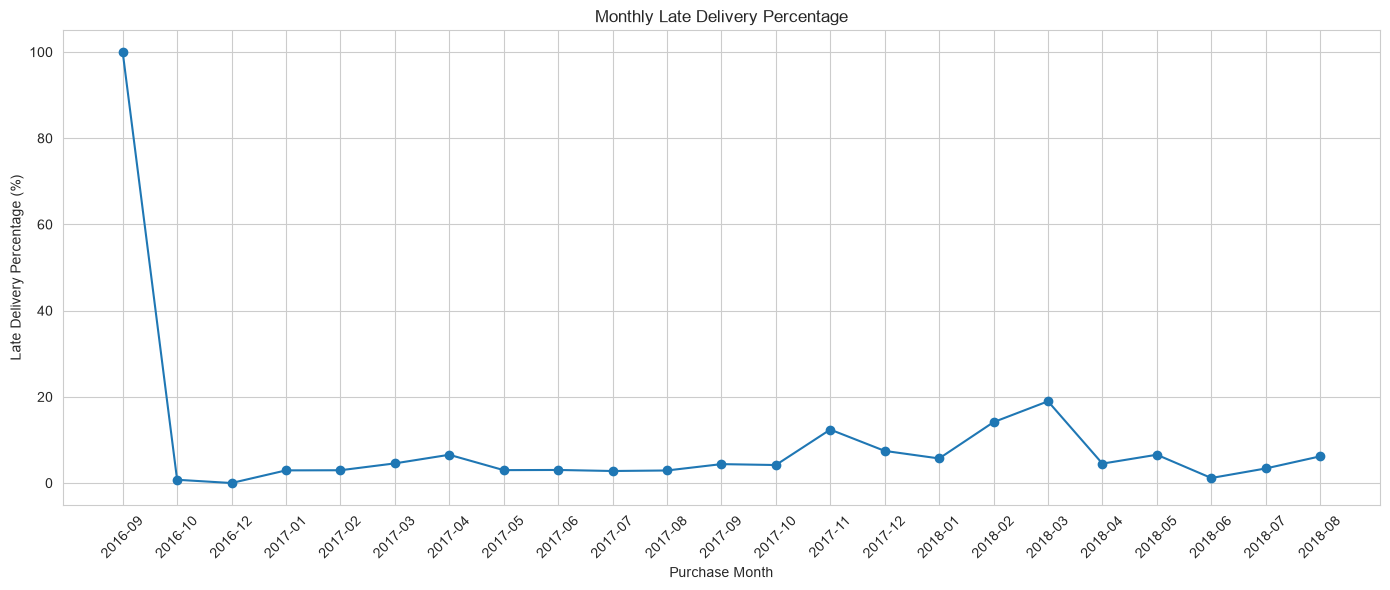

In [27]:
# Step 21: Monthly Late Delivery Analysis

monthly_analysis = ml_data_sorted.copy()

monthly_analysis["purchase_month_year"] = (
    monthly_analysis["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_trend = (
    monthly_analysis.groupby("purchase_month_year")
    .agg(
        total_orders=("late_delivery", "count"),
        late_orders=("late_delivery", "sum")
    )
)

monthly_trend["late_percentage"] = (
    monthly_trend["late_orders"] /
    monthly_trend["total_orders"] * 100
)

display(monthly_trend.round(2))

# Plot monthly late delivery percentage
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_trend.index.astype(str),
    monthly_trend["late_percentage"],
    marker="o"
)

plt.title("Monthly Late Delivery Percentage")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Percentage (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
# Step 22: Monthly Model Performance

test_results = pd.DataFrame({
    "purchase_timestamp": ml_data_sorted.iloc[split_index:][
        "order_purchase_timestamp"
    ].values,
    "actual": y_test.values,
    "predicted": final_predictions,
    "probability": test_probabilities
})

test_results["month"] = (
    pd.to_datetime(test_results["purchase_timestamp"])
    .dt.to_period("M")
)

monthly_model_performance = (
    test_results.groupby("month")
    .apply(
        lambda group: pd.Series({
            "total_orders": len(group),
            "actual_late": group["actual"].sum(),
            "actual_late_percentage": group["actual"].mean() * 100,
            "predicted_late": group["predicted"].sum(),
            "precision": precision_score(
                group["actual"],
                group["predicted"],
                zero_division=0
            ),
            "recall": recall_score(
                group["actual"],
                group["predicted"],
                zero_division=0
            )
        }),
        include_groups=False
    )
    .round(3)
)

display(monthly_model_performance)

,total_orders,actual_late,actual_late_percentage,predicted_late,precision,recall
month,,,,,,
2018-05,691.0,2.0,0.289,8.0,0.000,0.000
2018-06,6096.0,71.0,1.165,327.0,0.058,0.268
2018-07,6156.0,208.0,3.379,1042.0,0.074,0.370
2018-08,6351.0,393.0,6.188,1115.0,0.066,0.188


In [29]:
# Step 23: Compare Training and Testing Feature Distributions

distribution_comparison = pd.DataFrame({
    "Training_Mean": X_train[numerical_features].mean(),
    "Testing_Mean": X_test[numerical_features].mean(),
    "Training_Median": X_train[numerical_features].median(),
    "Testing_Median": X_test[numerical_features].median()
})

distribution_comparison["Mean_Difference_%"] = (
    (
        distribution_comparison["Testing_Mean"]
        - distribution_comparison["Training_Mean"]
    )
    / distribution_comparison["Training_Mean"].abs().replace(0, np.nan)
    * 100
)

display(distribution_comparison.round(2))

,Training_Mean,Testing_Mean,Training_Median,Testing_Median,Mean_Difference_%
purchase_year,2017.43,2018.00,2017.00,2018.00,0.03
purchase_month,5.80,6.94,5.00,7.00,19.61
purchase_day,15.54,15.44,15.00,16.00,-0.64
purchase_dayofweek,2.76,2.72,3.00,3.00,-1.52
purchase_hour,14.77,14.78,15.00,15.00,0.08
is_weekend,0.23,0.23,0.00,0.00,-0.32
estimated_delivery_days,24.97,22.00,24.00,21.00,-11.89
total_items,1.14,1.13,1.00,1.00,-0.81
unique_sellers,1.01,1.02,1.00,1.00,0.51
total_price,136.66,138.56,86.90,85.90,1.39


In [30]:
# Step 24: Compare Late Delivery Rates by Estimated Delivery Window

train_analysis = ml_data_sorted.iloc[:split_index].copy()
test_analysis = ml_data_sorted.iloc[split_index:].copy()

# Create bins using training data quartiles
bins = sorted(
    set(
        train_analysis["estimated_delivery_days"]
        .quantile([0, 0.25, 0.50, 0.75, 1])
        .astype(int)
        .tolist()
    )
)

# Ensure valid bin edges
bins = [-np.inf] + bins[1:-1] + [np.inf]

train_analysis["delivery_window_group"] = pd.cut(
    train_analysis["estimated_delivery_days"],
    bins=bins,
    include_lowest=True
)

test_analysis["delivery_window_group"] = pd.cut(
    test_analysis["estimated_delivery_days"],
    bins=bins,
    include_lowest=True
)

def delivery_window_summary(data, period):
    summary = (
        data.groupby("delivery_window_group", observed=False)
        .agg(
            total_orders=("late_delivery", "count"),
            late_orders=("late_delivery", "sum"),
            late_percentage=("late_delivery", "mean")
        )
    )

    summary["late_percentage"] *= 100
    summary["period"] = period

    return summary.reset_index()

window_comparison = pd.concat([
    delivery_window_summary(train_analysis, "Training"),
    delivery_window_summary(test_analysis, "Testing")
])

display(window_comparison.round(2))

,delivery_window_group,total_orders,late_orders,late_percentage,period
0,"(-inf, 20.0]",21356,1489,6.97,Training
1,"(20.0, 24.0]",18560,1701,9.16,Training
2,"(24.0, 29.0]",19039,1544,8.11,Training
3,"(29.0, inf]",18221,1126,6.18,Training
0,"(-inf, 20.0]",9308,523,5.62,Testing
1,"(20.0, 24.0]",2709,75,2.77,Testing
2,"(24.0, 29.0]",2832,42,1.48,Testing
3,"(29.0, inf]",4445,34,0.76,Testing


In [31]:
# Step 25: Prepare Recent Training Dataset

latest_training_date = ml_data_sorted.iloc[
    split_index - 1
]["order_purchase_timestamp"]

recent_cutoff = latest_training_date - pd.DateOffset(months=12)

recent_mask = (
    ml_data_sorted.iloc[:split_index]["order_purchase_timestamp"]
    >= recent_cutoff
)

X_recent = X_train.loc[recent_mask].copy()
y_recent = y_train.loc[recent_mask].copy()

print("Recent training cutoff:", recent_cutoff)

print("\nHistorical training records:", len(X_train))
print("Recent training records:", len(X_recent))

print("\nHistorical late delivery rate:",
      round(y_train.mean() * 100, 2), "%")

print("Recent late delivery rate:",
      round(y_recent.mean() * 100, 2), "%")

print("\nRecent training period:")
print(ml_data_sorted.loc[
    recent_mask[recent_mask].index[0],
    "order_purchase_timestamp"
])
print("to")
print(latest_training_date)

Recent training cutoff: 2017-05-26 18:16:57

Historical training records: 77176
Recent training records: 66671

Historical late delivery rate: 7.59 %
Recent late delivery rate: 8.14 %

Recent training period:
2017-05-26 18:31:02
to
2018-05-26 18:16:57


In [32]:
# Step 26: Train Recent-Data Logistic Regression

from sklearn.base import clone

# Keep only recent records belonging to the fitting period
recent_fit_indices = X_fit.index.intersection(X_recent.index)

X_recent_fit = X_recent.loc[recent_fit_indices]
y_recent_fit = y_recent.loc[recent_fit_indices]

print("Recent fitting records:", len(X_recent_fit))
print("Validation records:", len(X_val))

# Create an independent pipeline
recent_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train recent-data model
recent_model.fit(X_recent_fit, y_recent_fit)

# Predict on validation data
recent_val_probabilities = recent_model.predict_proba(X_val)[:, 1]

recent_val_predictions = (
    recent_val_probabilities >= 0.5
).astype(int)

print("\nRECENT MODEL VALIDATION RESULTS")
print("Accuracy:", round(
    accuracy_score(y_val, recent_val_predictions), 4
))
print("Precision:", round(
    precision_score(y_val, recent_val_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_val, recent_val_predictions, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_val, recent_val_predictions, zero_division=0), 4
))
print("ROC AUC:", round(
    roc_auc_score(y_val, recent_val_probabilities), 4
))

Recent fitting records: 51235
Validation records: 15436

RECENT MODEL VALIDATION RESULTS
Accuracy: 0.125
Precision: 0.0705
Recall: 0.9922
F1 Score: 0.1317
ROC AUC: 0.7187


In [33]:
# Step 27: Recent Model Threshold Comparison

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]

recent_threshold_results = []

for threshold in thresholds:

    predictions = (
        recent_val_probabilities >= threshold
    ).astype(int)

    recent_threshold_results.append({
        "Threshold": threshold,
        "Predicted_Late": predictions.sum(),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

recent_threshold_df = pd.DataFrame(
    recent_threshold_results
)

display(recent_threshold_df.round(4))

,Threshold,Predicted_Late,Precision,Recall,F1_Score
0,0.50,14523,0.0705,0.9922,0.1317
1,0.60,13264,0.0752,0.9671,0.1396
2,0.70,10013,0.0895,0.8682,0.1622
3,0.80,5492,0.1275,0.6783,0.2146
4,0.90,1404,0.1866,0.2539,0.2151
5,0.95,253,0.2055,0.0504,0.0809


In [34]:
# Step 28: Final Recent-Data Model

final_recent_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train on all recent training records
final_recent_model.fit(X_recent, y_recent)

# Predict on untouched test data
recent_test_probabilities = (
    final_recent_model.predict_proba(X_test)[:, 1]
)

selected_recent_threshold = 0.90

recent_test_predictions = (
    recent_test_probabilities >= selected_recent_threshold
).astype(int)

print("FINAL RECENT MODEL TEST RESULTS")
print("Threshold:", selected_recent_threshold)

print("Accuracy:", round(
    accuracy_score(y_test, recent_test_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, recent_test_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, recent_test_predictions, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, recent_test_predictions, zero_division=0), 4
))
print("ROC AUC:", round(
    roc_auc_score(y_test, recent_test_probabilities), 4
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, recent_test_predictions))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    recent_test_predictions,
    target_names=["On Time or Early", "Late"],
    zero_division=0
))

FINAL RECENT MODEL TEST RESULTS
Threshold: 0.9
Accuracy: 0.9264
Precision: 0.1006
Recall: 0.1395
F1 Score: 0.1169
ROC AUC: 0.685

CONFUSION MATRIX
[[17780   840]
 [  580    94]]

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

On Time or Early       0.97      0.95      0.96     18620
            Late       0.10      0.14      0.12       674

        accuracy                           0.93     19294
       macro avg       0.53      0.55      0.54     19294
    weighted avg       0.94      0.93      0.93     19294



In [35]:
# Step 28: Historical vs Recent Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Historical Logistic Regression",
        "Recent 12-Month Logistic Regression"
    ],
    "Accuracy": [0.8535, 0.9264],
    "Precision": [0.0682, 0.1006],
    "Recall": [0.2522, 0.1395],
    "F1_Score": [0.1074, 0.1169],
    "ROC_AUC": [0.6851, 0.6850]
})

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Historical Logistic Regression,0.8535,0.0682,0.2522,0.1074,0.6851
1,Recent 12-Month Logistic Regression,0.9264,0.1006,0.1395,0.1169,0.6850


In [36]:
# Step 29: Recent Model Feature Importance

# Get transformed feature names
feature_names = (
    recent_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get logistic regression coefficients
coefficients = (
    recent_model.named_steps["classifier"].coef_[0]
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 20 IMPORTANT FEATURES")

display(feature_importance.head(20).round(4))

TOP 20 IMPORTANT FEATURES


,Feature,Coefficient,Importance
0,num__purchase_year,1.8291,1.8291
90,cat__main_category_dvds_blu_ray,1.7670,1.7670
36,cat__customer_state_RR,1.5649,1.5649
121,cat__main_category_musica,1.5512,1.5512
16,cat__customer_state_AL,1.5329,1.5329
1,num__purchase_month,1.4393,1.4393
40,cat__customer_state_SP,-1.3522,1.3522
66,cat__main_category_artes,-1.3208,1.3208
110,cat__main_category_livros_importados,-1.3118,1.3118
18,cat__customer_state_AP,-1.2419,1.2419


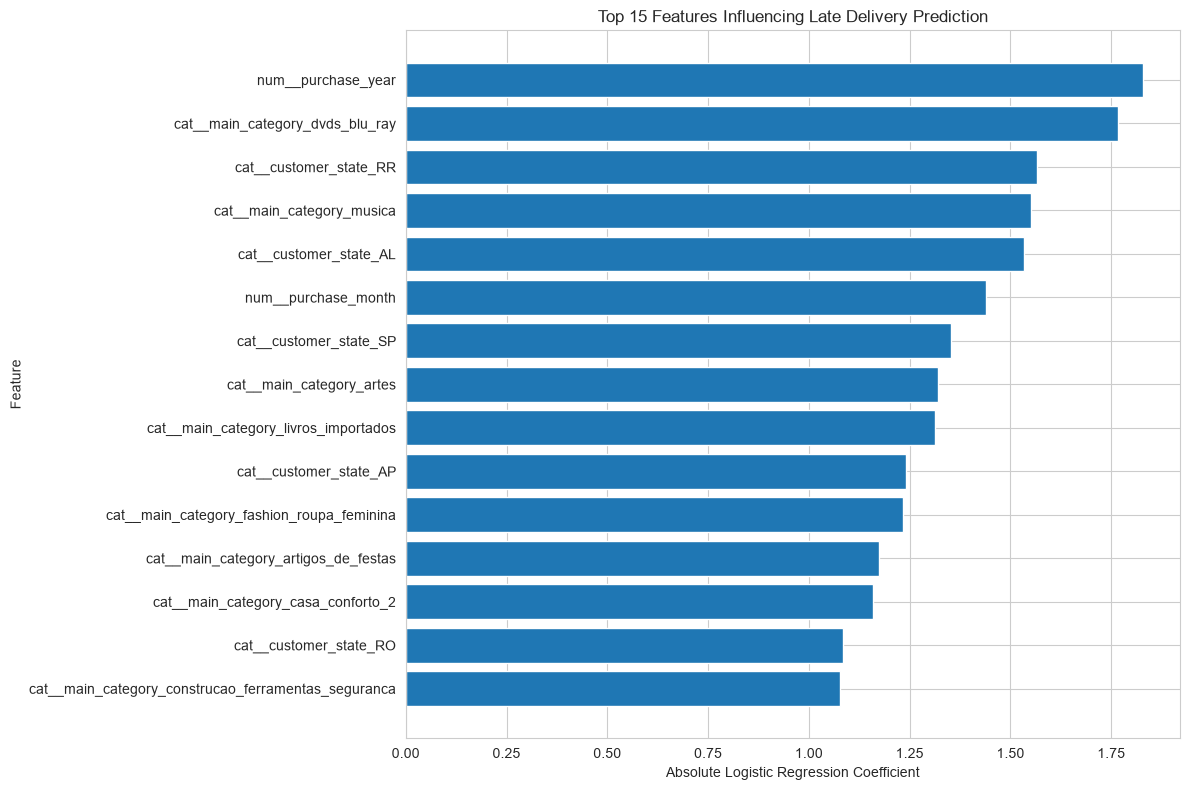

In [37]:
# Step 30: Visualize Top 15 Feature Importances

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Influencing Late Delivery Prediction")
plt.xlabel("Absolute Logistic Regression Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [38]:
# Step 31: Check Frequency of Top Categorical Features

top_categorical_features = [
    "customer_state",
    "main_category",
    "main_seller_state"
]

for column in top_categorical_features:

    print(f"\nTOP 15 VALUES IN {column.upper()}")

    frequency = (
        X_recent_fit[column]
        .value_counts(dropna=False)
        .head(15)
    )

    display(frequency.to_frame("Order_Count"))


TOP 15 VALUES IN CUSTOMER_STATE


,Order_Count
customer_state,
SP,20621
RJ,6855
MG,6130
RS,2980
PR,2555
SC,1960
BA,1771
GO,1109
ES,1104



TOP 15 VALUES IN MAIN_CATEGORY


,Order_Count
main_category,
cama_mesa_banho,5163
esporte_lazer,4330
beleza_saude,4075
informatica_acessorios,3696
moveis_decoracao,3175
relogios_presentes,2654
utilidades_domesticas,2589
brinquedos,2350
telefonia,2253



TOP 15 VALUES IN MAIN_SELLER_STATE


,Order_Count
main_seller_state,
SP,36574
MG,4090
PR,4056
RJ,2033
SC,1905
RS,907
DF,475
BA,355
GO,237


In [39]:
# Step 32: Investigate High-Coefficient Categories and States

feature_groups = {
    "customer_state": ["RR", "AL", "AP"],
    "main_category": [
        "dvds_blu_ray",
        "musica",
        "artes",
        "livros_importados",
        "fashion_roupa_feminina",
        "artigos_de_festas",
        "casa_conforto_2"
    ],
    "main_seller_state": ["MA"]
}

for column, values in feature_groups.items():

    print(f"\nLATE DELIVERY ANALYSIS: {column.upper()}")

    analysis_df = pd.DataFrame({
        column: X_recent_fit[column],
        "late_delivery": y_recent_fit
    })

    result = (
        analysis_df[
            analysis_df[column].isin(values)
        ]
        .groupby(column)
        .agg(
            total_orders=("late_delivery", "count"),
            late_orders=("late_delivery", "sum"),
            late_rate=("late_delivery", "mean")
        )
    )

    result["late_rate"] = result["late_rate"] * 100

    display(result.round(2))


LATE DELIVERY ANALYSIS: CUSTOMER_STATE


,total_orders,late_orders,late_rate
customer_state,,,
AL,207,55,26.57
AP,35,0,0.00
RR,19,3,15.79



LATE DELIVERY ANALYSIS: MAIN_CATEGORY


,total_orders,late_orders,late_rate
main_category,,,
artes,55,1,1.82
artigos_de_festas,15,0,0.00
casa_conforto_2,14,3,21.43
dvds_blu_ray,29,3,10.34
fashion_roupa_feminina,20,2,10.00
livros_importados,20,0,0.00
musica,9,1,11.11



LATE DELIVERY ANALYSIS: MAIN_SELLER_STATE


,total_orders,late_orders,late_rate
main_seller_state,,,
MA,37,6,16.22


In [40]:
# Step 33: Compare Category and State Patterns Across Periods

feature_groups = {
    "customer_state": ["AL", "RR", "AP"],
    "main_category": [
        "dvds_blu_ray",
        "musica",
        "artes",
        "livros_importados",
        "fashion_roupa_feminina",
        "artigos_de_festas",
        "casa_conforto_2"
    ],
    "main_seller_state": ["MA"]
}

for column, values in feature_groups.items():

    print(f"\n{column.upper()} - FITTING VS VALIDATION")

    fit_data = pd.DataFrame({
        column: X_recent_fit[column],
        "late_delivery": y_recent_fit
    })

    val_data = pd.DataFrame({
        column: X_val[column],
        "late_delivery": y_val
    })

    fit_data["period"] = "Recent Fitting"
    val_data["period"] = "Validation"

    combined = pd.concat([fit_data, val_data])

    result = (
        combined[combined[column].isin(values)]
        .groupby(["period", column])
        .agg(
            total_orders=("late_delivery", "count"),
            late_orders=("late_delivery", "sum"),
            late_rate=("late_delivery", "mean")
        )
        .reset_index()
    )

    result["late_rate"] *= 100

    display(result.round(2))


CUSTOMER_STATE - FITTING VS VALIDATION


,period,customer_state,total_orders,late_orders,late_rate
0,Recent Fitting,AL,207,55,26.57
1,Recent Fitting,AP,35,0,0.00
2,Recent Fitting,RR,19,3,15.79
3,Validation,AL,57,13,22.81
4,Validation,AP,12,0,0.00
5,Validation,RR,3,1,33.33



MAIN_CATEGORY - FITTING VS VALIDATION


,period,main_category,total_orders,late_orders,late_rate
0,Recent Fitting,artes,55,1,1.82
1,Recent Fitting,artigos_de_festas,15,0,0.00
2,Recent Fitting,casa_conforto_2,14,3,21.43
3,Recent Fitting,dvds_blu_ray,29,3,10.34
4,Recent Fitting,fashion_roupa_feminina,20,2,10.00
5,Recent Fitting,livros_importados,20,0,0.00
6,Recent Fitting,musica,9,1,11.11
7,Validation,artes,62,5,8.06
8,Validation,artigos_de_festas,3,0,0.00
9,Validation,dvds_blu_ray,10,0,0.00



MAIN_SELLER_STATE - FITTING VS VALIDATION


,period,main_seller_state,total_orders,late_orders,late_rate
0,Recent Fitting,MA,37,6,16.22
1,Validation,MA,126,43,34.13


In [41]:
# Step 34: Permutation Feature Importance

from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    recent_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
)

display(permutation_importance_df.round(5))

,Feature,Importance_Mean,Importance_Std
7,customer_state,0.07037,0.00168
6,estimated_delivery_days,0.03071,0.00120
14,average_freight,0.01505,0.00272
8,main_seller_state,0.00829,0.00059
2,purchase_day,0.00708,0.00244
13,average_price,0.00634,0.00360
11,total_price,0.00367,0.00099
10,unique_sellers,0.00087,0.00063
4,purchase_hour,0.00062,0.00022
3,purchase_dayofweek,0.00015,0.00009


In [42]:
# Step 35: Select Important Features

selected_features = [
    "customer_state",
    "estimated_delivery_days",
    "average_freight",
    "main_seller_state",
    "purchase_day",
    "average_price",
    "total_price"
]

X_recent_fit_reduced = X_recent_fit[selected_features].copy()
X_val_reduced = X_val[selected_features].copy()
X_test_reduced = X_test[selected_features].copy()
X_recent_reduced = X_recent[selected_features].copy()

print("Selected features:", selected_features)
print("Reduced fitting shape:", X_recent_fit_reduced.shape)
print("Reduced validation shape:", X_val_reduced.shape)
print("Reduced testing shape:", X_test_reduced.shape)

Selected features: ['customer_state', 'estimated_delivery_days', 'average_freight', 'main_seller_state', 'purchase_day', 'average_price', 'total_price']
Reduced fitting shape: (51235, 7)
Reduced validation shape: (15436, 7)
Reduced testing shape: (19294, 7)


In [43]:
# Step 36: Train Reduced Logistic Regression Model

from sklearn.base import clone

reduced_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

reduced_model.fit(X_recent_fit_reduced, y_recent_fit)

print("Reduced Logistic Regression model trained successfully!")

ValueError: Some column names are not columns of the dataframe: {'purchase_month', 'total_freight', 'purchase_hour', 'unique_categories', 'purchase_dayofweek', 'total_items', 'unique_sellers', 'is_weekend', 'average_product_weight', 'purchase_year'}

In [44]:
# Step 36: Train Reduced Logistic Regression Model

from sklearn.base import clone

# Identify numerical and categorical features
reduced_numerical_features = (
    X_recent_fit_reduced
    .select_dtypes(include=np.number)
    .columns.tolist()
)

reduced_categorical_features = (
    X_recent_fit_reduced
    .select_dtypes(include=["object", "str", "category"])
    .columns.tolist()
)

# Create numerical preprocessing
reduced_numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create categorical preprocessing
reduced_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Create a new preprocessor for only 7 features
reduced_preprocessor = ColumnTransformer(
    transformers=[
        ("num", reduced_numerical_transformer, reduced_numerical_features),
        ("cat", reduced_categorical_transformer, reduced_categorical_features)
    ]
)

# Build reduced model
reduced_model = Pipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train model
reduced_model.fit(X_recent_fit_reduced, y_recent_fit)

print("Reduced Logistic Regression model trained successfully!")
print("Numerical features:", len(reduced_numerical_features))
print("Categorical features:", len(reduced_categorical_features))

Reduced Logistic Regression model trained successfully!
Numerical features: 5
Categorical features: 2


In [45]:
# Step 37: Reduced Model Validation Predictions

reduced_val_probabilities = reduced_model.predict_proba(
    X_val_reduced
)[:, 1]

threshold_results = []

for threshold in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]:

    predictions = (
        reduced_val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Predicted_Late": predictions.sum(),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1_Score": f1_score(y_val, predictions, zero_division=0)
    })

reduced_threshold_results = pd.DataFrame(threshold_results)

display(reduced_threshold_results.round(4))

,Threshold,Predicted_Late,Precision,Recall,F1_Score
0,0.50,5319,0.1307,0.6734,0.2189
1,0.60,3040,0.1661,0.4893,0.2480
2,0.70,1221,0.2105,0.2490,0.2281
3,0.80,265,0.2302,0.0591,0.0941
4,0.90,49,0.2245,0.0107,0.0204
5,0.95,20,0.1500,0.0029,0.0057


In [46]:
# Step 38: Final Reduced Model Evaluation

selected_reduced_threshold = 0.60

final_reduced_model = Pipeline(steps=[
    ("preprocessor", clone(reduced_preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train on all recent training data
final_reduced_model.fit(X_recent_reduced, y_recent)

# Predict on untouched test data
reduced_test_probabilities = final_reduced_model.predict_proba(
    X_test_reduced
)[:, 1]

reduced_test_predictions = (
    reduced_test_probabilities >= selected_reduced_threshold
).astype(int)

# Calculate metrics
print("FINAL REDUCED MODEL PERFORMANCE")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, reduced_test_predictions), 4))
print("Precision:", round(precision_score(y_test, reduced_test_predictions), 4))
print("Recall:", round(recall_score(y_test, reduced_test_predictions), 4))
print("F1 Score:", round(f1_score(y_test, reduced_test_predictions), 4))
print("ROC AUC:", round(roc_auc_score(y_test, reduced_test_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, reduced_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    reduced_test_predictions,
    target_names=["On Time or Early", "Late"],
    zero_division=0
))

FINAL REDUCED MODEL PERFORMANCE
----------------------------------------
Accuracy: 0.7569
Precision: 0.0516
Recall: 0.3427
F1 Score: 0.0897
ROC AUC: 0.6818

Confusion Matrix:
[[14373  4247]
 [  443   231]]

Classification Report:
                  precision    recall  f1-score   support

On Time or Early       0.97      0.77      0.86     18620
            Late       0.05      0.34      0.09       674

        accuracy                           0.76     19294
       macro avg       0.51      0.56      0.47     19294
    weighted avg       0.94      0.76      0.83     19294



In [47]:
# Step 39: Final Model Comparison

final_comparison = pd.DataFrame({
    "Model": [
        "Historical Logistic Regression",
        "Recent 12-Month Logistic Regression",
        "Reduced Logistic Regression"
    ],
    "Features": [18, 18, 7],
    "Threshold": [0.80, 0.90, 0.60],
    "Accuracy": [0.8535, 0.9264, 0.7569],
    "Precision": [0.0682, 0.1006, 0.0516],
    "Recall": [0.2522, 0.1395, 0.3427],
    "F1_Score": [0.1074, 0.1169, 0.0897],
    "ROC_AUC": [0.6851, 0.6850, 0.6818]
})

display(
    final_comparison
    .sort_values("F1_Score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Model,Features,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Recent 12-Month Logistic Regression,18,0.9,0.9264,0.1006,0.1395,0.1169,0.6850
1,Historical Logistic Regression,18,0.8,0.8535,0.0682,0.2522,0.1074,0.6851
2,Reduced Logistic Regression,7,0.6,0.7569,0.0516,0.3427,0.0897,0.6818


## Final Machine Learning Findings

### Project Objective
Developed machine learning models to predict whether an e-commerce order would arrive later than its estimated delivery date.

### Models Evaluated
- Logistic Regression using historical training data.
- Logistic Regression trained on the most recent 12 months of training data.
- Reduced Logistic Regression using seven selected features.

### Best Model
The Recent 12-Month Logistic Regression model achieved the best test F1-score among the three evaluated models.

| Metric | Test Result |
|---|---:|
| Accuracy | 92.64% |
| Precision | 10.06% |
| Recall | 13.95% |
| F1-score | 11.69% |
| ROC-AUC | 68.50% |

### Key Findings
- Customer state and estimated delivery duration were the most influential features according to permutation importance.
- Delivery patterns changed substantially over time.
- Training and testing data showed differences in late-delivery rates, indicating temporal distribution changes.
- Training on recent data slightly improved F1-score compared with historical training.
- Reducing the feature set did not improve final test performance.

### Limitations
- Late deliveries represented a small minority of the dataset.
- Model precision and recall remain insufficient for dependable operational use.
- Temporal changes reduced the reliability of validation-based model selection.
- The model identifies associations, not causes of delivery delays.

### Conclusion
The experiments demonstrate the challenges of predicting late deliveries in imbalanced and time-dependent e-commerce data. The recent-data Logistic Regression model performed best among the tested alternatives, but further improvements in feature engineering, temporal validation, and model calibration are necessary before practical deployment.